## Lead localization

In [1]:
import os
import cv2
import torch
import shutil
from tqdm import tqdm
from ultralytics import YOLO
import random
import numpy as np
import PIL.Image as Image
import PIL.ImageEnhance as ImageEnhance

In [5]:
model_path = "" # Fill with your own path
input_folder = "" # Fill with your own path
output_folder = "" # Fill with your own path

normal_folder = os.path.join(output_folder, "normal")
overlap_folder = os.path.join(output_folder, "overlap")
os.makedirs(normal_folder, exist_ok=True)
os.makedirs(overlap_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = YOLO(model_path)
model.to(device)

bbox_csv_path = os.path.join(output_folder, "bbox_cropped_overlap.csv")
overlap_csv_path = os.path.join(output_folder, "overlap_metadata.csv")

In [7]:
def degrade_ecg_image(img):
    """
    img: numpy.ndarray (BGR, uint8)
    """
    img = img.copy()

    if random.random() < 0.5:
        noise = np.random.normal(0, 25, img.shape).astype(np.int16)
        img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    if random.random() < 0.3:
        k = random.choice([3, 5])
        img = cv2.GaussianBlur(img, (k, k), 0)

    if random.random() < 0.3:
        for _ in range(random.randint(1, 3)):
            center = (
                random.randint(0, img.shape[1] - 1),
                random.randint(0, img.shape[0] - 1),
            )
            radius = random.randint(3, 10)
            color = random.choice([(100, 100, 100), (200, 200, 200)])
            cv2.circle(img, center, radius, color, -1)

    if random.random() < 0.7:
        pil_img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        pil_img = ImageEnhance.Brightness(pil_img).enhance(random.uniform(0.7, 1.3))
        pil_img = ImageEnhance.Contrast(pil_img).enhance(random.uniform(0.7, 1.3))
        img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    return img

In [4]:
if not os.path.exists(bbox_csv_path):
    with open(bbox_csv_path, "w") as f:
        f.write(
            "filename,index,label,conf,x1,y1,x2,y2,"
            "crop_w,crop_h,w_orig,h_orig,"
            "bbox_center_x,bbox_center_y\n"
        )

if not os.path.exists(overlap_csv_path):
    with open(overlap_csv_path, "w") as f:
        f.write(
            "filename,lead1_idx,lead2_idx,lead1_label,lead2_label,"
            "overlap_x1,overlap_y1,overlap_x2,overlap_y2,"
            "overlap_area,overlap_w,overlap_h,iou,"
            "lead1_area,lead2_area\n"
        )

In [7]:
def calculate_iou(box1, box2):
    x1_1, y1_1, x2_1, y2_1 = box1
    x1_2, y1_2, x2_2, y2_2 = box2

    x1_i = max(x1_1, x1_2)
    y1_i = max(y1_1, y1_2)
    x2_i = min(x2_1, x2_2)
    y2_i = min(y2_1, y2_2)

    if x2_i <= x1_i or y2_i <= y1_i:
        return None

    overlap_area = (x2_i - x1_i) * (y2_i - y1_i)
    area1 = (x2_1 - x1_1) * (y2_1 - y1_1)
    area2 = (x2_2 - x1_2) * (y2_2 - y1_2)

    iou = overlap_area / (area1 + area2 - overlap_area)

    return {
        "x1": x1_i, "y1": y1_i, "x2": x2_i, "y2": y2_i,
        "overlap_area": overlap_area,
        "overlap_w": x2_i - x1_i,
        "overlap_h": y2_i - y1_i,
        "iou": iou,
        "area1": area1,
        "area2": area2
    }

In [6]:
def visualize_with_overlap(img, lead_boxes, filename, save_dir):
    vis = img.copy()

    # Draw boxes
    for lead in lead_boxes.values():
        x1, y1, x2, y2 = lead["bbox"]
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Draw overlaps
    lead_indices = list(lead_boxes.keys())
    for i in range(len(lead_indices)):
        for j in range(i + 1, len(lead_indices)):
            overlap = calculate_iou(
                lead_boxes[lead_indices[i]]["bbox"],
                lead_boxes[lead_indices[j]]["bbox"]
            )
            if overlap:
                cv2.rectangle(
                    vis,
                    (overlap["x1"], overlap["y1"]),
                    (overlap["x2"], overlap["y2"]),
                    (0, 0, 255),
                    2
                )

    os.makedirs(save_dir, exist_ok=True)
    cv2.imwrite(os.path.join(save_dir, filename), vis)


In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

def visualize_with_overlap(img, lead_boxes, title="ECG Visualization"):
    """
    Visualize detected ECG leads with overlaps.
    Shows all leads regardless of confidence. 
    Low-confidence boxes (<0.25) are drawn in orange.
    """
    # Convert BGR (OpenCV) to RGB for matplotlib
    vis = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    fig, ax = plt.subplots(1, figsize=(12, 6))
    ax.imshow(vis)

    # Draw boxes for each lead
    for lead in lead_boxes.values():
        x1, y1, x2, y2 = lead["bbox"]
        conf = lead.get("conf", 1.0)  # default to 1.0 if not present

        # Green for high-confidence (>=0.25), blue for low-confidence (<0.25)
        color = 'limegreen' if conf >= 0.25 else 'blue'

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=1,
            edgecolor='blue',
            facecolor='none'
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 5, f"{lead['label']}", 
            color='blue', fontsize=10, fontweight='bold'
        )

    # Draw overlaps in red
    # lead_indices = list(lead_boxes.keys())
    # for i in range(len(lead_indices)):
    #     for j in range(i + 1, len(lead_indices)):
    #         overlap = calculate_iou(
    #             lead_boxes[lead_indices[i]]["bbox"],
    #             lead_boxes[lead_indices[j]]["bbox"]
    #         )
    #         if overlap:
    #             rect = patches.Rectangle(
    #                 (overlap["x1"], overlap["y1"]),
    #                 overlap["x2"] - overlap["x1"],
    #                 overlap["y2"] - overlap["y1"],
    #                 linewidth=1,
    #                 edgecolor='red',
    #                 facecolor='none'
    #             )
    #             ax.add_patch(rect)

    # ax.set_title(title)
    ax.axis('off')
    plt.show()


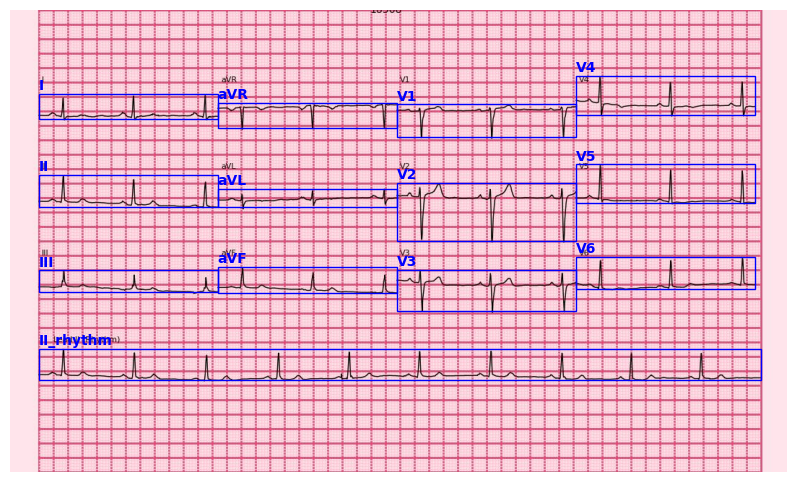

In [15]:
import os
import cv2
from tqdm import tqdm

# Replace this with your single image path
image_path = "" # Fill with your own path

# Load the image
img = cv2.imread(image_path)
if img is None:
    raise FileNotFoundError(f"Cannot read image: {image_path}")

h_orig, w_orig = img.shape[:2]

# Run your YOLO model
results = model(
    img,
    conf=0.25,
    imgsz=640,
    device=device,
    verbose=False
)

lead_boxes = {}
for box in results[0].boxes:
    cls = int(box.cls[0])
    conf = float(box.conf[0])
    label = results[0].names[cls]

    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w_orig, x2), min(h_orig, y2)

    lead_boxes[cls] = {
        "bbox": (x1, y1, x2, y2),
        "label": label,
        "conf": conf,
        "bbox_center_x": (x1 + x2) / 2,
        "bbox_center_y": (y1 + y2) / 2
    }

# Check for overlapping boxes
overlapping_leads = set()
lead_indices = list(lead_boxes.keys())
for i in range(len(lead_indices)):
    for j in range(i + 1, len(lead_indices)):
        lead1 = lead_boxes[lead_indices[i]]
        lead2 = lead_boxes[lead_indices[j]]
        overlap = calculate_iou(lead1["bbox"], lead2["bbox"])
        if overlap:
            overlapping_leads.add(lead_indices[i])
            overlapping_leads.add(lead_indices[j])

# Visualize results
visualize_with_overlap(
    img, lead_boxes, os.path.basename(image_path)
)
